### Step 1: Pre-Formulate Your Hypothesis (Prediction)

* **Prediction:** Metal objects, being generally smoother and denser than irregular rocks, are expected to have a higher overall average echo energy reflection across frequency bins.
* **Null Hypothesis ($H_0$):** The true difference in average echo energy between Rock and Metal is zero ($H_0: \mu_{\text{Metal}} - \mu_{\text{Rock}} = 0$).
* **Alternative Hypothesis ($H_1$):** The true difference in average echo energy between Rock and Metal is not zero ($H_1: \mu_{\text{Metal}} - \mu_{\text{Rock}} \neq 0$).

In [2]:
!pip install gdown
!gdown --folder "https://drive.google.com/drive/folders/19BhHY3PUZ35FMsQQiq6Zaw6mRK1WgHF1?usp=sharing"

Retrieving folder contents
Processing file 1JLsnFzYnjJqAupaa_vIlA2BAh2zOr_5v uci_sonar_clean.xlsx
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1JLsnFzYnjJqAupaa_vIlA2BAh2zOr_5v
To: /content/UCI_Sonar_Data/uci_sonar_clean.xlsx
100% 109k/109k [00:00<00:00, 107MB/s]
Download completed


In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/content/UCI_Sonar_Data/uci_sonar_clean.xlsx'
df = pd.read_excel(file_path)

# Filter to only get the actual 60 energy bin columns
energy_cols = [col for col in df.columns if col.lower().startswith('energy_bin_')]
print(f"Correctly detected {len(energy_cols)} energy bin columns.")

# Step 2: Calculate the Per-Return Means (across the 60 energy bins)
df['row_mean'] = df[energy_cols].mean(axis=1)

# Identify the class column (contains 'rock'/'mine' or labels)
class_col = 'class_name' if 'class_name' in df.columns else df.columns[-1]
print(f"Using column '{class_col}' as the class column.")

# Group the per-return summary numbers into Group R and Group M
# In this dataset, the labels are typically 'rock' (Rock) and 'mine' (Metal)
group_r = df[df[class_col].str.lower().str.startswith('r')]['row_mean']
group_m = df[df[class_col].str.lower().str.startswith('m')]['row_mean']

print(f"Group R (Rock) count: {len(group_r)}, mean energy: {group_r.mean():.4f}")
print(f"Group M (Metal) count: {len(group_m)}, mean energy: {group_m.mean():.4f}")

Correctly detected 60 energy bin columns.
Using column 'class_name' as the class column.
Group R (Rock) count: 97, mean energy: 0.2697
Group M (Metal) count: 111, mean energy: 0.2915


In [4]:
# Step 3 & 4: Welch's t-Test and Confidence Interval

# Welch's t-test
t_stat, p_val = stats.ttest_ind(group_m, group_r, equal_var=False)

# Degrees of Freedom (Welch–Satterthwaite equation)
n1, n2 = len(group_m), len(group_r)
s1, s2 = group_m.var(ddof=1), group_r.var(ddof=1)
df_welch = ((s1/n1 + s2/n2)**2) / (((s1/n1)**2 / (n1 - 1)) + ((s2/n2)**2 / (n2 - 1)))

# Calculate the 95% Confidence Interval for Difference of Means (Metal - Rock)
mean_diff = group_m.mean() - group_r.mean()
se_diff = np.sqrt(s1/n1 + s2/n2)
t_critical = stats.t.ppf(0.975, df=df_welch)

margin_of_error = t_critical * se_diff
confidence_interval = (mean_diff - margin_of_error, mean_diff + margin_of_error)

print(f"Welch's t-statistic: {t_stat:.4f}")
print(f"Degrees of Freedom: {df_welch:.2f}")
print(f"p-value: {p_val:.4e}")
print(f"95% Confidence Interval for (Mean_Metal - Mean_Rock): ({confidence_interval[0]:.6f}, {confidence_interval[1]:.6f})")
print(f"t-critical: {t_critical:.4f}")

if p_val < 0.05:
    print("\nResult: Reject the null hypothesis. The difference in average echo energy is statistically significant.")
else:
    print("\nResult: Fail to reject the null hypothesis. The difference is not statistically significant.")

Welch's t-statistic: 4.1353
Degrees of Freedom: 189.94
p-value: 5.3165e-05
95% Confidence Interval for (Mean_Metal - Mean_Rock): (0.011436, 0.032295)
t-critical: 1.9725

Result: Reject the null hypothesis. The difference in average echo energy is statistically significant.


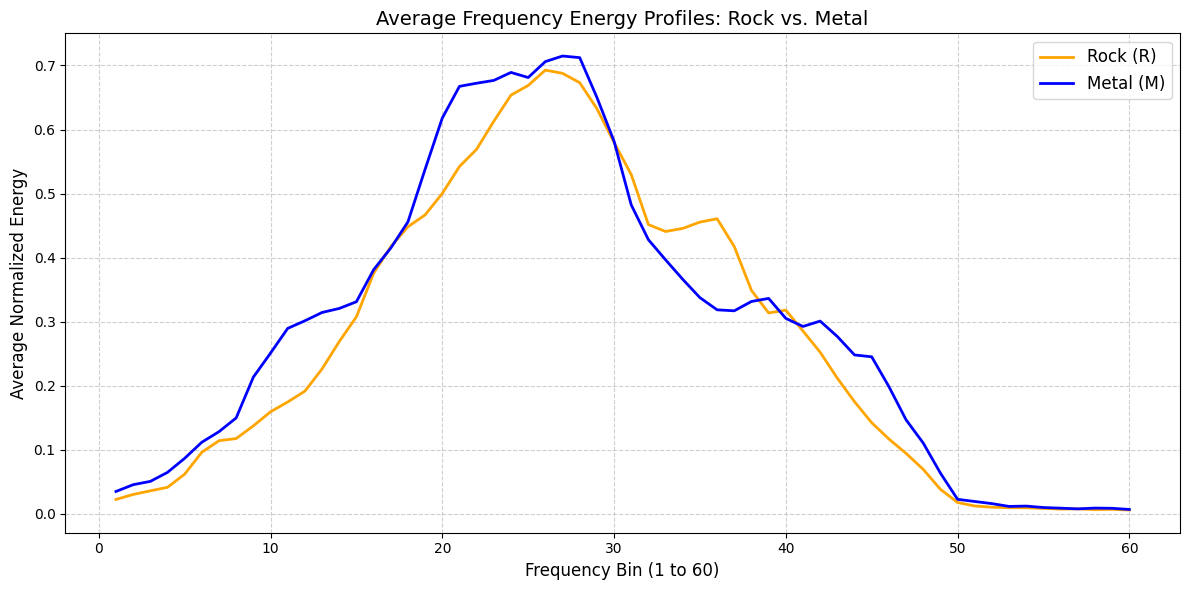

In [5]:
# Step 5: Plot the Average Profiles

# Separate energy bins for Rock and Metal
rock_profile = df[df[class_col].str.lower().str.startswith('r')][energy_cols].mean()
metal_profile = df[df[class_col].str.lower().str.startswith('m')][energy_cols].mean()

plt.figure(figsize=(12, 6))
plt.plot(range(1, 61), rock_profile, label='Rock (R)', color='orange', linewidth=2)
plt.plot(range(1, 61), metal_profile, label='Metal (M)', color='blue', linewidth=2)

plt.title('Average Frequency Energy Profiles: Rock vs. Metal', fontsize=14)
plt.xlabel('Frequency Bin (1 to 60)', fontsize=12)
plt.ylabel('Average Normalized Energy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()